# SLIIT — Faculty of Computing
## IT5022: Fundamentals of Machine Learning
### Supervised Learning: NYC Taxi Trip Duration Prediction

---

### 1. Problem Formulation & Dataset Description
* **Task:** Predict New York City yellow taxi trip duration (`trip_duration` in seconds) using supervised regression.
* **Dataset:** NYC Taxi Trip Duration Dataset ([Kaggle](https://www.kaggle.com/c/nyc-taxi-trip-duration)).
* **Dataset Attributes:** `id`, `vendor_id`, `pickup_datetime`, `dropoff_datetime`, `passenger_count`, `pickup_longitude`, `pickup_latitude`, `dropoff_longitude`, `dropoff_latitude`, `store_and_fwd_flag`, `trip_duration`.
* **Algorithms Evaluated:**
  1. **Random Forest Regressor** (Ensemble Bagging)
  2. **XGBoost Regressor** (Extreme Gradient Boosting)
* **Evaluation Metrics:** Root Mean Squared Logarithmic Error (RMSLE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Coefficient of Determination ($R^2$).

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})

### 2. Full Dataset Ingestion

In [3]:
data_path = 'Datasets/nyc-taxi-trip-duration/train.csv'
if not os.path.exists(data_path):
    data_path = '../Datasets/nyc-taxi-trip-duration/train.csv'

# Load complete dataset without downsampling
df = pd.read_csv(data_path)

print(f"Total records ingested: {len(df):,}")
print(f"Total attributes: {df.shape[1]}")
df.info()
df.head()

Total records ingested: 1,458,644
Total attributes: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


### 3. Data Cleaning & Quality Audit

In [4]:
# 1. Audit and drop missing values
null_counts = df.isnull().sum()
print("Missing values per column:\n", null_counts)
df = df.dropna()

# 2. Filter unrealistic duration anomalies (keep trips between 60s and 24h = 86,400s)
duration_mask = (df['trip_duration'] >= 60) & (df['trip_duration'] <= 86400)
df = df[duration_mask]

# 3. Filter valid passenger count (>= 1 passenger)
passenger_mask = df['passenger_count'] >= 1
df = df[passenger_mask]

# 4. Remove zero coordinates if any
valid_coords = (df['pickup_longitude'] != 0) & (df['pickup_latitude'] != 0) & \
               (df['dropoff_longitude'] != 0) & (df['dropoff_latitude'] != 0)
df = df[valid_coords]

print(f"\nCleaned dataset size: {len(df):,} records ({len(df) / 1_458_644 * 100:.2f}% retained).")

Missing values per column:
 id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

Cleaned dataset size: 1,450,027 records (99.41% retained).


### 4. Feature Engineering

In [5]:
# Datetime features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
df['month'] = df['pickup_datetime'].dt.month
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['is_rush_hour'] = df['hour'].isin([7, 8, 9, 16, 17, 18, 19]).astype(int)

# Great-circle Haversine distance (km)
lat1, lon1 = np.radians(df['pickup_latitude']), np.radians(df['pickup_longitude'])
lat2, lon2 = np.radians(df['dropoff_latitude']), np.radians(df['dropoff_longitude'])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
df['haversine_km'] = 6371.0 * 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))

# Manhattan distance approximation (km)
df['manhattan_km'] = 111.0 * (np.abs(df['dropoff_latitude'] - df['pickup_latitude']) +
                              np.abs(df['dropoff_longitude'] - df['pickup_longitude']))

# Bearing (compass direction angle)
df['bearing'] = np.degrees(np.arctan2(
    np.sin(dlon) * np.cos(lat2),
    np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
))

# Filter zero displacement records
df = df[df['haversine_km'] > 0.05]

# Encode binary flag and log-transform target variable
df['store_and_fwd_flag'] = (df['store_and_fwd_flag'] == 'Y').astype(int)
df['log_duration'] = np.log1p(df['trip_duration'])

print(f"Engineered feature set ready. Total rows: {len(df):,}")

Engineered feature set ready. Total rows: 1,443,792


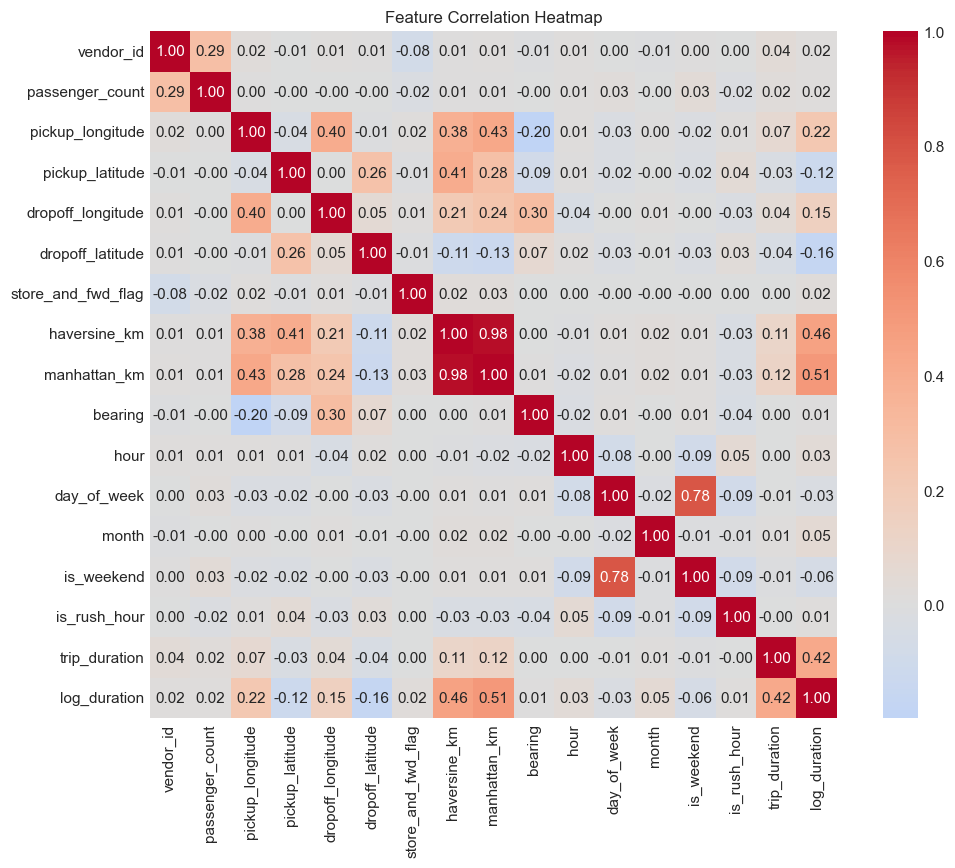

In [6]:
features = [
    'vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
    'haversine_km', 'manhattan_km', 'bearing',
    'hour', 'day_of_week', 'month', 'is_weekend', 'is_rush_hour'
]

# Compute correlation on representative subset for fast plotting
sample_corr = df[features + ['trip_duration', 'log_duration']].sample(n=100_000, random_state=42).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(sample_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()